# Deep Learning Statistical Arbitrage : exécution et analyse complète

Ce notebook déroule tout le pipeline du papier *Deep Learning Statistical Arbitrage*
(Guijarro-Ordonez, Pelger, Zanotti) sur un Mac Apple Silicon, sans modifier le code d'origine :

1. **Environnement** : versions, device (CPU / MPS)
2. **Données** : les résidus des modèles factoriels (IPCA, PCA, Fama-French)
3. **Extraction du signal** : OU, Fourier, cumsum sur un exemple réel
4. **Modèles d'allocation** : architectures, nombre de paramètres, vitesse
5. **Backtest glissant** : lancement du projet (ou rechargement d'un run existant)
6. **Résultats** : métriques, rendements cumulés, drawdowns, Sharpe glissant, années, distribution
7. **Analyse des poids** : nombre de positions, concentration, long/short
8. **Sensibilité aux coûts de transaction**
9. **Comparaison avec des stratégies de référence** : OU à seuil (Avellaneda-Lee), OU linéaire, reversal, 1/N
10. **Synthèse**

Voir aussi `explanation.md` pour l'explication détaillée du dépôt.

## 0. Paramètres

In [1]:
# --- Backtest ---------------------------------------------------------------
CONFIG = "configs/ouffn-full.yaml"   # n'importe quelle config de configs/
RUN_BACKTEST = False      # True : relance le backtest (OUFFN complet ≈ 35 min sur CPU M4)
NUM_EPOCHS = None         # None = valeur de la config (100) ; ex. 5 pour un essai rapide
FACTOR_MODELS = []        # [] = tous ceux de la config ; ex. ["PCA:5"]
DEVICE = "cpu"            # "cpu" ou "mps"
RESULTS_TAG = "notebook"  # tag du run lancé depuis ce notebook

# Run à recharger si RUN_BACKTEST = False (None = le plus récent du modèle)
LOAD_RESULTS_TAG = "full-cpu"

# --- Analyses ---------------------------------------------------------------
LOOKBACK = 30
LENGTH_TRAINING = 1000    # début de la période de test (jours)

## 1. Environnement

In [2]:
import os, sys, glob, gzip, shutil, pickle, subprocess, time, platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "local"))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib

import run_local  # lanceur Mac (importe run_train_test / train_test)
from preprocess import preprocess_ou, preprocess_fourier, preprocess_cumsum
from utils import import_string

%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
torch.autograd.set_detect_anomaly(False)

print("Racine du dépôt :", ROOT)
print("Python   :", sys.version.split()[0], platform.machine())
for m in (np, pd, torch, matplotlib, yaml):
    print(f"{m.__name__:<10} {m.__version__}")
print("MPS disponible :", torch.backends.mps.is_available())

Racine du dépôt : /Users/gauthier/Projects/dlsa-public
Python   : 3.13.5 arm64
numpy      2.5.4
pandas     2.3.3
torch      2.14.1
matplotlib 3.10.9
yaml       6.0.3
MPS disponible : True


In [3]:
with open(CONFIG) as f:
    config = yaml.safe_load(f)
MODEL_NAME = config["model_name"]
print(yaml.safe_dump(config, sort_keys=False, allow_unicode=True))

mode: test
results_tag: ''
debug: false
model_name: OUFFN
model:
  lookback: 30
  dropout: 0.25
  hidden_units:
  - 4
  - 4
  - 4
  - 4
preprocess_func: preprocess_ou
use_residual_weights: false
cap_proportion: 0.01
factor_models:
  IPCA:
  - 5
  PCA:
  - 5
  FamaFrench:
  - 5
perturbation: {}
num_epochs: 100
optimizer_name: Adam
optimizer_opts:
  lr: 0.001
batch_size: 125
retrain_freq: 125
rolling_retrain: true
force_retrain: true
length_training: 1000
early_stopping: false
objective: sharpe
market_frictions: false
trans_cost: 0
hold_cost: 0



## 2. Les données : résidus des modèles factoriels

Chaque fichier est une matrice **jours × actifs** de rendements résiduels quotidiens
(rendement de l'action moins sa partie expliquée par K facteurs), calculés hors échantillon de 1998 à 2016.
Un `0` signifie que l'actif n'est pas dans l'univers ce jour-là.

In [4]:
def residual_path(family, k, cap=0.01):
    # mêmes noms de fichiers que run_train_test.run()
    return {
        "IPCA": f"residuals/ipca_normalized/IPCA_DailyOOSresiduals_{k}_factors_420_initialMonths_240_window_12_reestimationFreq_{cap}_cap.npy",
        "PCA": f"residuals/pca/AvPCA_OOSresiduals_{k}_factors_1998_initialOOSYear_60_rollingWindow_252_covWindow_{cap}_Cap.npy",
        "FamaFrench": f"residuals/famafrench/DailyFamaFrench_OOSresiduals_{k}_factors_1998_initialOOSYear_60_rollingWindow_{cap}_Cap.npy",
    }[family]

def load_residuals(family, k):
    path = residual_path(family, k)
    if not os.path.exists(path):  # décompresse comme run() : le .gz d'origine est conservé
        with gzip.open(path + ".gz", "rb") as f_in, open(path, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)
    R = np.load(path).astype(np.float32)
    R[np.isnan(R)] = 0
    return R

inventory = []
for f in sorted(glob.glob("residuals/*/*.npy.gz")):
    family = f.split("/")[1]
    k = int(f.split("_factors")[0].split("_")[-1])
    inventory.append((family, k, os.path.getsize(f) / 1e6))
pd.DataFrame(inventory, columns=["famille", "K facteurs", "taille .gz (Mo)"]).pivot_table(
    index="famille", columns="K facteurs", values="taille .gz (Mo)")

K facteurs,0,1,2,3,4,5,8,10,15
famille,,,,,,,,,
famafrench,38.1557,39.7986,39.8069,39.8052,39.8021,39.8013,39.7957,NaN,NaN
ipca_normalized,38.1613,39.8031,NaN,39.8057,NaN,39.8061,39.8044,39.8029,39.7997
pca,38.1356,39.7912,NaN,39.7790,NaN,39.7722,39.7664,39.7627,39.7497


In [5]:
# Dates de bourse (même source que run_train_test.run())
run_local.prepare_dates_file()
ff = pd.read_csv(run_local.FF5_PATH, index_col=0)
dates = pd.to_datetime(ff.index[(ff.index > 19980000) & (ff.index < 20170000)].astype(str), format="%Y%m%d")

# Les résidus utilisés par la config
SETS = [(fam, k) for fam, ks in config["factor_models"].items() for k in ks]
if FACTOR_MODELS:
    SETS = [(s.split(":")[0], int(s.split(":")[1])) for s in FACTOR_MODELS]
residuals = {f"{fam}{k}": load_residuals(fam, k) for fam, k in SETS}

rows = []
for name, R in residuals.items():
    active = (R != 0)
    nz = R[active]
    rows.append({
        "résidus": name, "jours": R.shape[0], "actifs": R.shape[1],
        "actifs jamais actifs": int((active.sum(0) == 0).sum()),
        "actifs actifs / jour (moy.)": active.sum(1).mean(),
        "% observations non nulles": 100 * active.mean(),
        "moyenne (bp/j)": 1e4 * nz.mean(), "écart-type (%/j)": 100 * nz.std(),
        "skew": pd.Series(nz).skew(), "kurtosis": pd.Series(nz).kurt(),
    })
assert len(dates) == next(iter(residuals.values())).shape[0]
print(f"{len(dates)} jours de bourse, du {dates[0]:%Y-%m-%d} au {dates[-1]:%Y-%m-%d}")
pd.DataFrame(rows).set_index("résidus")

4781 jours de bourse, du 1998-01-02 au 2016-12-30


,jours,actifs,actifs jamais actifs,actifs actifs / jour (moy.),% observations non nulles,moyenne (bp/j),écart-type (%/j),skew,kurtosis
résidus,,,,,,,,,
IPCA5,4781,9483,7054,853.8187,9.0037,0.4834,2.1984,0.4071,49.7925
PCA5,4781,9483,7054,853.1772,8.9969,0.2567,1.9509,0.3451,50.7412
FamaFrench5,4781,9483,7054,853.6854,9.0023,0.3278,2.2767,0.3459,42.6306


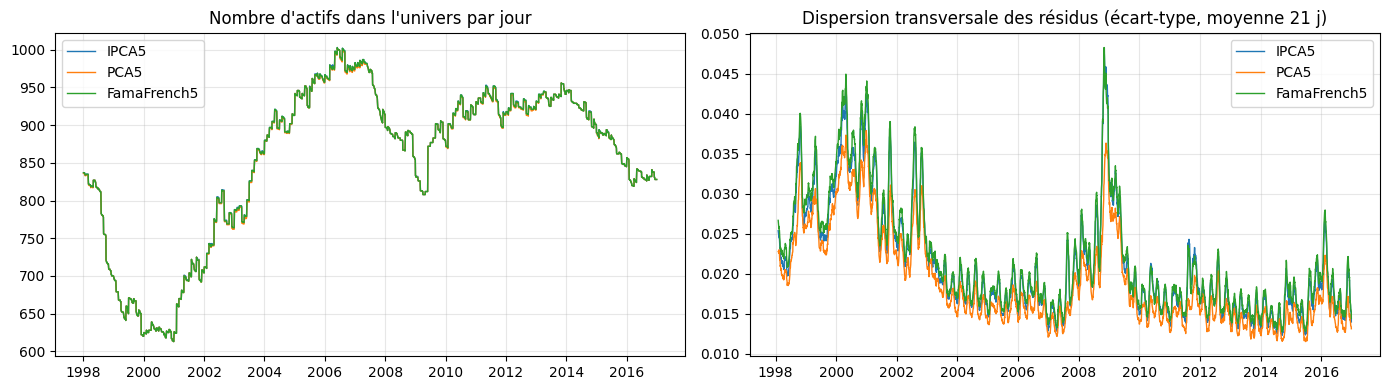

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, R in residuals.items():
    active = R != 0
    axes[0].plot(dates, active.sum(1), label=name, lw=1)
    xs = np.where(active, R, np.nan)
    axes[1].plot(dates, pd.Series(np.nanstd(xs, axis=1), index=dates).rolling(21).mean(), label=name, lw=1)
axes[0].set_title("Nombre d'actifs dans l'univers par jour")
axes[1].set_title("Dispersion transversale des résidus (écart-type, moyenne 21 j)")
axes[0].legend(); axes[1].legend()
plt.tight_layout()

### Retour à la moyenne

L'arbitrage statistique suppose que les résidus **reviennent vers leur moyenne**. Une autocorrélation négative
des rendements résiduels à court terme en est un indice.

In [7]:
def mean_autocorr(R, lag, min_obs=250):
    acs = []
    for j in np.where((R != 0).sum(0) >= min_obs)[0]:
        x = R[:, j]
        x = x[x != 0]
        if x.std() > 0:
            acs.append(np.corrcoef(x[:-lag], x[lag:])[0, 1])
    return np.nanmean(acs)

lags = [1, 2, 3, 5, 10]
pd.DataFrame({name: [mean_autocorr(R, l) for l in lags] for name, R in residuals.items()},
             index=pd.Index(lags, name="lag (jours)")).T.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.1, vmax=0.1)

lag (jours),1,2,3,5,10
IPCA5,-0.0215,-0.0145,-0.0049,-0.0078,-0.0003
PCA5,-0.0228,-0.0087,-0.0020,-0.0007,-0.0015
FamaFrench5,-0.0183,-0.0104,-0.0049,-0.0025,-0.0020


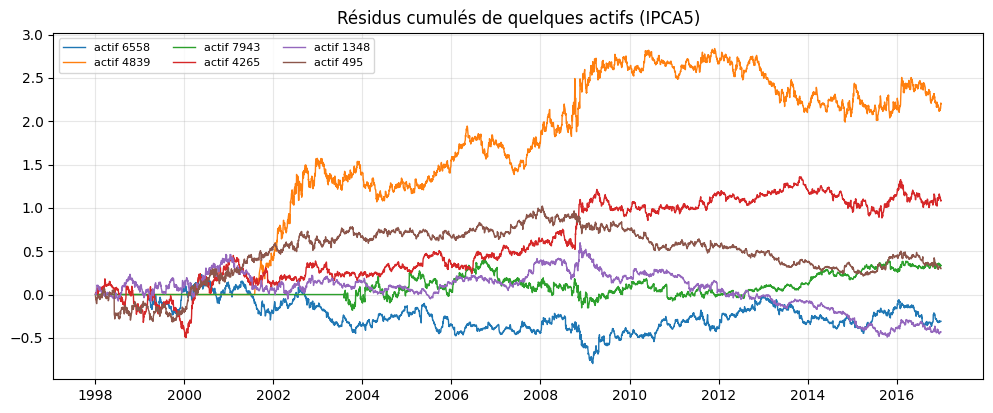

In [8]:
name0, R0 = next(iter(residuals.items()))
rng = np.random.default_rng(1)
candidates = np.where((R0 != 0).sum(0) > 3000)[0]
fig, ax = plt.subplots()
for j in rng.choice(candidates, 6, replace=False):
    ax.plot(dates, np.cumsum(R0[:, j]), lw=1, label=f"actif {j}")
ax.set_title(f"Résidus cumulés de quelques actifs ({name0})")
ax.legend(ncol=3, fontsize=8)

## 3. Extraction du signal

Sur chaque fenêtre de `lookback` = 30 jours, la trajectoire cumulée du résidu est transformée en signal :

- **cumsum** : la trajectoire brute (30 valeurs), utilisée par `RawFFN` et `CNNTransformer` ;
- **Fourier** : ses coefficients de Fourier (30 valeurs), pour `FourierFFN` ;
- **OU** : ajustement d'un processus d'Ornstein-Uhlenbeck, X(t+1) = a + b·X(t) + e, qui donne
  4 features : dernière valeur, moyenne d'équilibre μ = a/(1−b), volatilité d'équilibre σ et R².
  On ne garde que les actifs pour lesquels 0 < b < 1 (processus qui revient à la moyenne). Utilisé par `OUFFN`.

Exemple sur une fenêtre réelle :

Features OU : dernière valeur=-0.0768  μ=-0.0413  σ=0.0257  R²=0.306
s-score = (x − μ)/σ = -1.38  -> sélectionné (0<b<1) : True


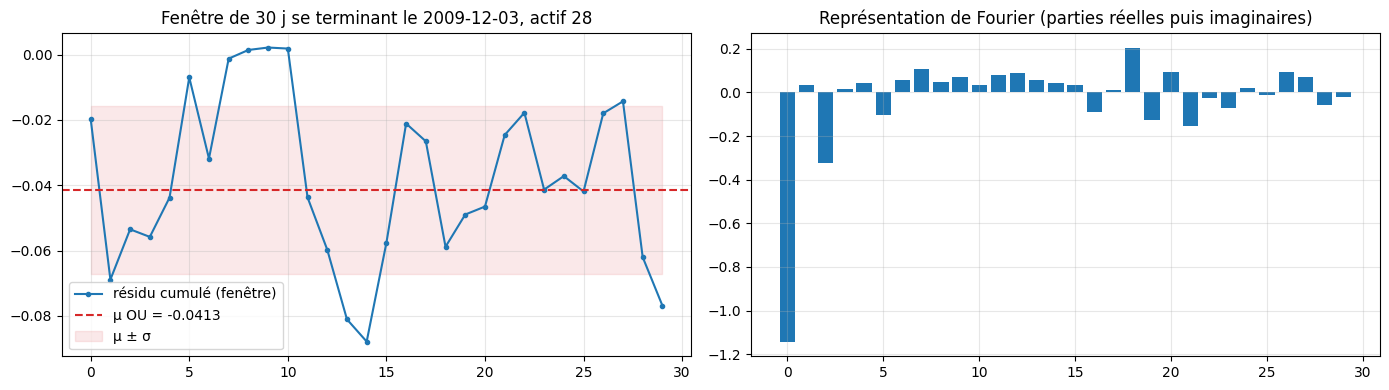

In [9]:
t_end, j = 3000, candidates[0]
sub = R0[t_end - LOOKBACK - 1 : t_end, :][:, [j]]       # 31 jours -> 1 fenêtre
w_cum, _ = preprocess_cumsum(sub, LOOKBACK)
w_fou, _ = preprocess_fourier(sub, LOOKBACK)
w_ou, sel_ou = preprocess_ou(sub, LOOKBACK)
x_last, mu, sigma, r2 = w_ou[0, 0]
s_score = (x_last - mu) / sigma

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(w_cum[0, 0], marker="o", ms=3, label="résidu cumulé (fenêtre)")
axes[0].axhline(mu, color="C3", ls="--", label=f"μ OU = {mu:.4f}")
axes[0].fill_between(range(LOOKBACK), mu - sigma, mu + sigma, color="C3", alpha=0.1, label="μ ± σ")
axes[0].set_title(f"Fenêtre de {LOOKBACK} j se terminant le {dates[t_end-1]:%Y-%m-%d}, actif {j}")
axes[0].legend()
axes[1].bar(range(LOOKBACK), w_fou[0, 0])
axes[1].set_title("Représentation de Fourier (parties réelles puis imaginaires)")
plt.tight_layout()
print(f"Features OU : dernière valeur={x_last:.4f}  μ={mu:.4f}  σ={sigma:.4f}  R²={r2:.3f}")
print(f"s-score = (x − μ)/σ = {s_score:+.2f}  -> sélectionné (0<b<1) : {bool(sel_ou[0, 0])}")

In [10]:
# Coût du préprocessing sur une fenêtre d'entraînement réelle (1000 jours)
block = R0[:LENGTH_TRAINING]
block = block[:, np.count_nonzero(block, axis=0) >= LOOKBACK]
timing = []
for f in (preprocess_ou, preprocess_fourier, preprocess_cumsum):
    t0 = time.perf_counter(); w, sel = f(block, LOOKBACK); dt = time.perf_counter() - t0
    timing.append({"fonction": f.__name__, "sortie": str(w.shape), "Mo": w.nbytes / 1e6,
                   "% (jour, actif) utilisables": 100 * sel.float().mean().item(), "secondes": dt})
pd.DataFrame(timing).set_index("fonction")

,sortie,Mo,"% (jour, actif) utilisables",secondes
fonction,,,,
preprocess_ou,"(970, 1234, 4)",19.1517,50.7330,0.2375
preprocess_fourier,"(970, 1234, 30)",143.6376,52.9068,0.2718
preprocess_cumsum,"(970, 1234, 30)",143.6376,52.9068,0.0946


## 4. Modèles d'allocation

Chaque modèle prend le signal **d'un actif** et renvoie un poids. Les paramètres sont partagés par tous les actifs.
Les poids d'une journée sont ensuite normalisés pour que Σ|w| = 1.

In [11]:
MODEL_CONFIGS = {Path(p).stem: yaml.safe_load(open(p)) for p in sorted(glob.glob("configs/*.yaml"))}
rows, models = [], {}
for cname, cfg in MODEL_CONFIGS.items():
    cls = import_string(f"models.{cfg['model_name']}.{cfg['model_name']}")
    m = cls(logdir="/tmp", **cfg["model"])
    models[cfg["model_name"]] = (m, cfg)
    rows.append({"config": cname, "modèle": cfg["model_name"], "préprocessing": cfg["preprocess_func"],
                 "paramètres": sum(p.numel() for p in m.parameters()), "hyperparamètres": cfg["model"]})
pd.DataFrame(rows).set_index("config")

,modèle,préprocessing,paramètres,hyperparamètres
config,,,,
cnntransformer-full,CNNTransformer,preprocess_cumsum,769,"{'lookback': 30, 'dropout': 0.25, 'filter_numb..."
fourierffn-full,FourierFFN,preprocess_fourier,673,"{'lookback': 30, 'dropout': 0.25, 'hidden_unit..."
ouffn-full,OUFFN,preprocess_ou,65,"{'lookback': 30, 'dropout': 0.25, 'hidden_unit..."
rawffn-full,RawFFN,preprocess_cumsum,673,"{'lookback': 30, 'dropout': 0.25, 'hidden_unit..."


In [12]:
print(models["CNNTransformer"][0])

CNNTransformer(
  (convBlocks): ModuleList(
    (0): CNN_Block(
      (conv1): Conv1d(1, 8, kernel_size=(2,), stride=(1,))
      (conv2): Conv1d(8, 8, kernel_size=(2,), stride=(1,))
      (relu): ReLU(inplace=True)
      (left_zero_padding): ConstantPad1d(padding=(1, 0), value=0)
      (normalization1): InstanceNorm1d(1, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
      (normalization2): InstanceNorm1d(8, eps=1e-05, momentum=0.1, affine=False, bias=False, track_running_stats=False)
    )
  )
  (encoder): TransformerEncoderLayer(
    (self_attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=8, out_features=8, bias=True)
    )
    (linear1): Linear(in_features=8, out_features=16, bias=True)
    (dropout): Dropout(p=0.25, inplace=False)
    (linear2): Linear(in_features=16, out_features=8, bias=True)
    (norm1): LayerNorm((8,), eps=1e-05, elementwise_affine=True, bias=True)
    (norm2): LayerNorm((8,), eps=1e-05, elem

In [13]:
# Vitesse d'un forward + backward sur 2000 actifs (une journée typique)
def n_features(cfg):
    return 4 if cfg["preprocess_func"] == "preprocess_ou" else cfg["model"]["lookback"]

devices = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else [])
rows = []
for name, (m, cfg) in models.items():
    for dev in devices:
        mm = m.to(dev); x = torch.randn(2000, n_features(cfg), device=dev)
        for _ in range(3): mm(x).sum().backward()          # warm-up
        if dev == "mps": torch.mps.synchronize()
        t0 = time.perf_counter()
        for _ in range(20): mm(x).sum().backward()
        if dev == "mps": torch.mps.synchronize()
        rows.append({"modèle": name, "device": dev, "ms / itération": 1000 * (time.perf_counter() - t0) / 20})
    m.to("cpu")
pd.DataFrame(rows).pivot(index="modèle", columns="device", values="ms / itération")

device,cpu,mps
modèle,,
CNNTransformer,142.2964,16.2445
FourierFFN,0.4699,0.4694
OUFFN,0.2761,0.3953
RawFFN,0.3732,0.4287


## 5. Backtest glissant

`train_test.test()` entraîne un modèle sur 1000 jours (≈ 4 ans) en maximisant le **Sharpe**, l'applique
sur les 125 jours suivants (≈ 6 mois), puis décale la fenêtre. On obtient ainsi environ 15 ans de rendements
hors échantillon (2002 à 2016).

Le backtest passe par `local/run_local.py`, qui appelle `run_train_test.run()` sur CPU ou MPS sans
modifier le code. Il tourne dans un sous-processus et son log est écrit dans `logs/`.
Avec `RUN_BACKTEST = False`, le dernier run existant est rechargé ; s'il n'y en a pas, un essai court
est lancé (5 époques, PCA 5).

In [14]:
def find_results(model_name, tag=None):
    files = sorted(glob.glob(f"results/{model_name}/results_*.pickle"), key=os.path.getmtime)
    if tag:
        files = [f for f in files if Path(f).stem.split("_", 2)[-1].startswith(tag)]
    return files[-1] if files else None

def launch(config_path, num_epochs=None, factor_models=(), device="cpu", tag="notebook"):
    cmd = [sys.executable, "local/run_local.py", "-c", config_path, "--device", device, "--results-tag", tag]
    if num_epochs: cmd += ["--num-epochs", str(num_epochs)]
    for fm in factor_models: cmd += ["--factor-model", fm]
    os.makedirs("logs", exist_ok=True)
    log_path = f"logs/notebook_{time.strftime('%Y%m%d-%H%M%S')}.log"
    print("Commande :", " ".join(cmd), "\nLog :", log_path)
    t0 = time.time()
    with open(log_path, "w") as log:
        proc = subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT)
    print(f"Terminé en {(time.time()-t0)/60:.1f} min, code de retour {proc.returncode}")
    lines = open(log_path).read().splitlines()
    print("\n".join(l for l in lines if "==> Sharpe" in l or "Testing" in l or "Error" in l))
    if proc.returncode != 0:
        print("\n".join(lines[-30:]))
        raise RuntimeError("le backtest a échoué")

results_file = None if RUN_BACKTEST else find_results(MODEL_NAME, LOAD_RESULTS_TAG) or find_results(MODEL_NAME)
if results_file is None:
    if RUN_BACKTEST:
        launch(CONFIG, NUM_EPOCHS, FACTOR_MODELS, DEVICE, RESULTS_TAG)
    else:
        print("Aucun résultat existant : essai court (5 époques, PCA 5)")
        launch(CONFIG, 5, ["PCA:5"], DEVICE, RESULTS_TAG)
    results_file = find_results(MODEL_NAME, RESULTS_TAG)
print("Résultats :", results_file)

Résultats : results/OUFFN/results_safe-tetra_full-cpu1793185823.pickle


In [15]:
with open(results_file, "rb") as f:
    raw_results = pickle.load(f)

def short_name(tag):
    return tag.split("__")[0]

res = {}
for tag, r in raw_results.items():
    n = len(r["returns"])
    idx = dates[-n:]
    res[short_name(tag)] = {
        "tag": tag,
        "returns": pd.Series(r["returns"], index=idx),
        "turnover": pd.Series(r["turnover"], index=idx),
        "short_proportion": pd.Series(r["short_proportion"], index=idx),
        "config": r["config"], "timestamp": r["timestamp"],
    }
cfg_run = next(iter(res.values()))["config"]
print(f"{len(res)} jeu(x) de résidus : {list(res)}")
print(f"Run du {next(iter(res.values()))['timestamp']:%Y-%m-%d %H:%M} — {cfg_run['num_epochs']} époques, "
      f"objectif {cfg_run['objective']}, période de test {idx[0]:%Y-%m-%d} → {idx[-1]:%Y-%m-%d} ({n} jours)")

3 jeu(x) de résidus : ['IPCA5', 'PCA5', 'FamaFrench5']
Run du 2026-10-28 11:39 — 100 époques, objectif sharpe, période de test 2001-12-26 → 2016-12-30 (3781 jours)


## 6. Résultats

### Métriques principales

Rendement et volatilité sont annualisés (× 252, × √252). Le Sharpe est calculé sans taux sans risque :
les résidus sont déjà des rendements en excès. Turnover et part de positions courtes sont calculés en espace
**résidus**, car les matrices de composition ne sont pas fournies (`use_residual_weights: False`).

In [16]:
def drawdown(r):
    wealth = (1 + r).cumprod()
    return wealth / wealth.cummax() - 1

def metrics(r, turnover=None, short=None):
    ann_ret, ann_vol = 252 * r.mean(), np.sqrt(252) * r.std()
    dd = drawdown(r)
    out = {
        "Sharpe": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "Rendement ann. (%)": 100 * ann_ret,
        "Volatilité ann. (%)": 100 * ann_vol,
        "Sortino": ann_ret / (np.sqrt(252) * r[r < 0].std()),
        "Max drawdown (%)": 100 * dd.min(),
        "Calmar": ann_ret / -dd.min() if dd.min() < 0 else np.nan,
        "% jours positifs": 100 * (r > 0).mean(),
        "Skew": r.skew(), "Kurtosis": r.kurt(),
        "Pire jour (%)": 100 * r.min(), "Meilleur jour (%)": 100 * r.max(),
    }
    if turnover is not None:
        out["Turnover moyen"] = turnover.mean()
        out["Part short moyenne"] = short.mean()
    return out

summary = pd.DataFrame({k: metrics(v["returns"], v["turnover"], v["short_proportion"]) for k, v in res.items()}).T
summary.index.name = f"{MODEL_NAME} sur"
summary.style.format("{:.2f}").background_gradient(subset=["Sharpe"], cmap="Greens")

,Sharpe,Rendement ann. (%),Volatilité ann. (%),Sortino,Max drawdown (%),Calmar,% jours positifs,Skew,Kurtosis,Pire jour (%),Meilleur jour (%),Turnover moyen,Part short moyenne
OUFFN sur,,,,,,,,,,,,,
IPCA5,0.64,1.28,2.01,0.90,-5.23,0.24,53.37,-0.18,2.93,-0.76,0.63,0.05,0.10
PCA5,0.85,0.62,0.73,1.28,-1.97,0.31,52.95,-0.19,1.42,-0.26,0.21,0.04,0.00
FamaFrench5,0.19,0.67,3.51,0.27,-12.65,0.05,50.91,0.11,6.96,-1.49,2.19,0.05,0.00


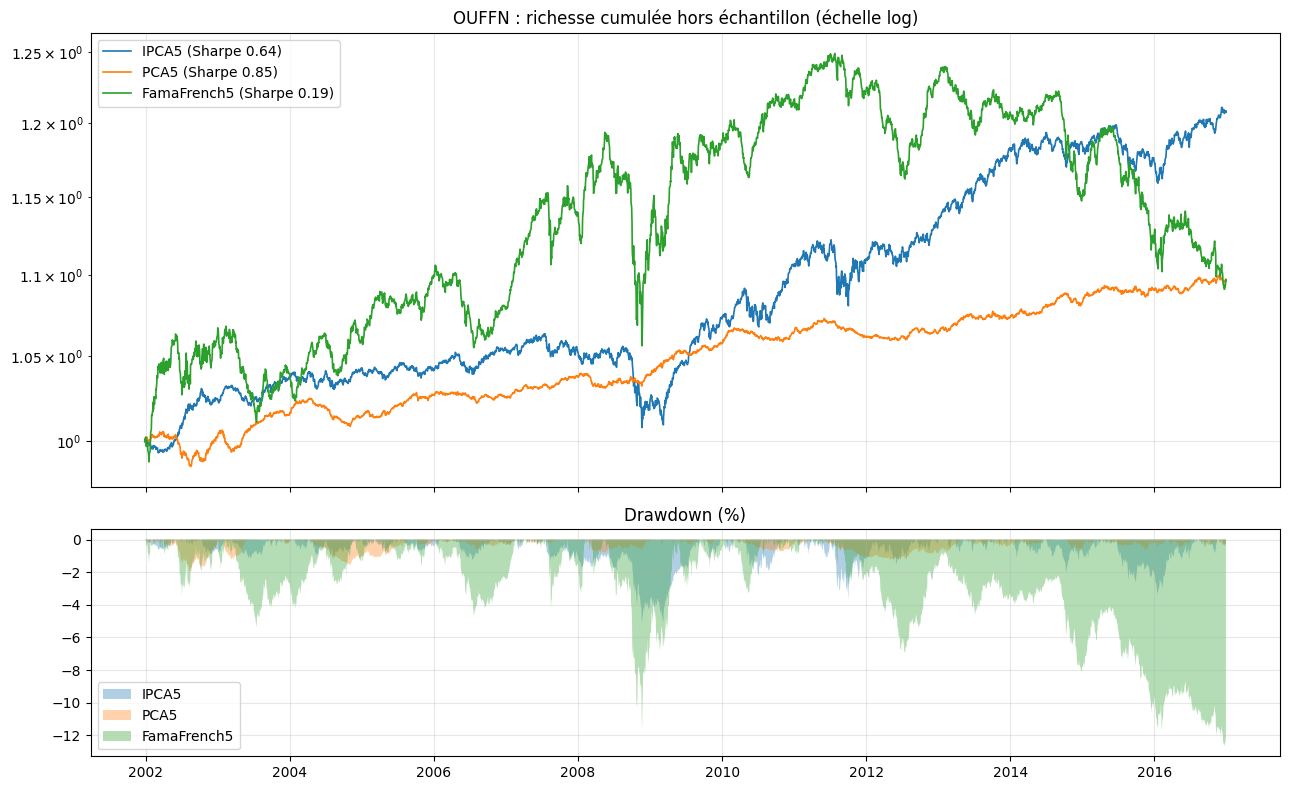

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for k, v in res.items():
    r = v["returns"]
    axes[0].plot((1 + r).cumprod(), label=f"{k} (Sharpe {summary.loc[k, 'Sharpe']:.2f})", lw=1.2)
    axes[1].fill_between(r.index, 100 * drawdown(r), alpha=0.35, label=k)
axes[0].set_yscale("log"); axes[0].set_title(f"{MODEL_NAME} : richesse cumulée hors échantillon (échelle log)")
axes[0].legend(); axes[1].set_title("Drawdown (%)"); axes[1].legend()
plt.tight_layout()

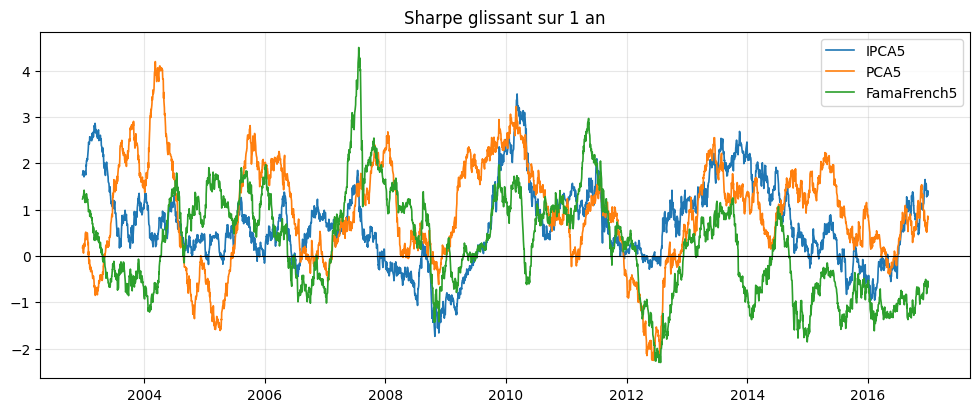

In [18]:
fig, ax = plt.subplots()
for k, v in res.items():
    r = v["returns"]
    ax.plot(np.sqrt(252) * r.rolling(252).mean() / r.rolling(252).std(), label=k, lw=1.2)
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Sharpe glissant sur 1 an"); ax.legend()

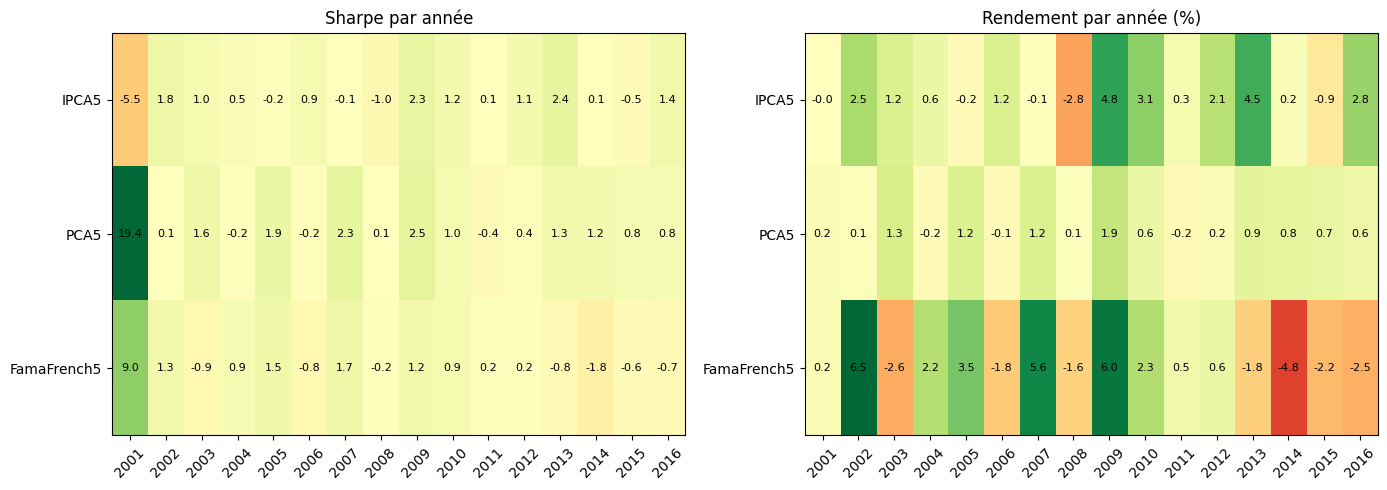

In [19]:
annual = pd.DataFrame({k: v["returns"].groupby(v["returns"].index.year).apply(
            lambda r: np.sqrt(252) * r.mean() / r.std()) for k, v in res.items()})
annual_ret = pd.DataFrame({k: v["returns"].groupby(v["returns"].index.year).apply(
            lambda r: 100 * ((1 + r).prod() - 1)) for k, v in res.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, tab, title, cmap in [(axes[0], annual, "Sharpe par année", "RdYlGn"),
                             (axes[1], annual_ret, "Rendement par année (%)", "RdYlGn")]:
    lim = np.nanmax(np.abs(tab.values))
    im = ax.imshow(tab.T.values, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(tab.index)), tab.index, rotation=45)
    ax.set_yticks(range(len(tab.columns)), tab.columns)
    for (i, j), val in np.ndenumerate(tab.T.values):
        ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); ax.grid(False)
plt.tight_layout()

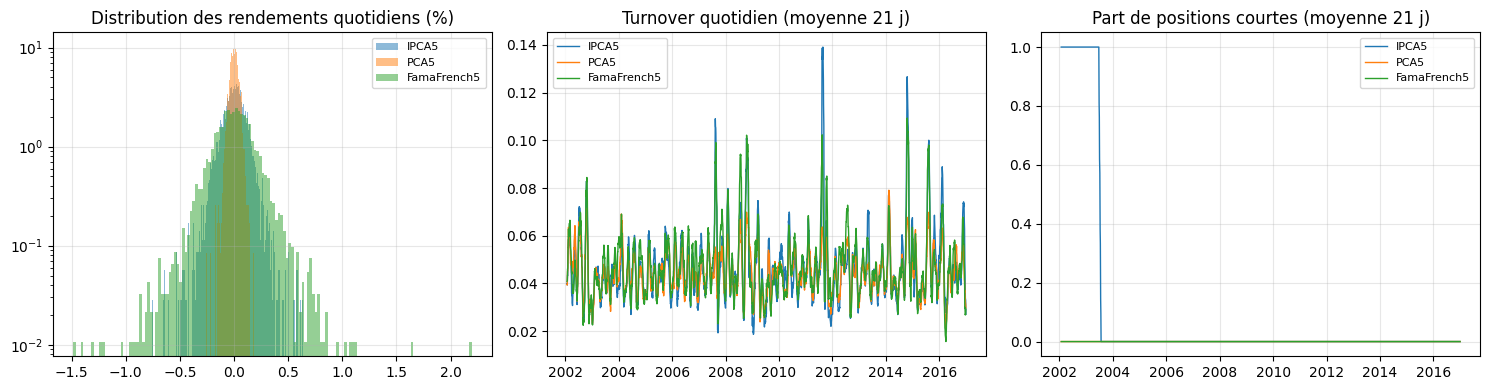

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, v in res.items():
    axes[0].hist(100 * v["returns"], bins=150, alpha=0.5, label=k, density=True)
    axes[1].plot(v["turnover"].rolling(21).mean(), label=k, lw=1)
    axes[2].plot(v["short_proportion"].rolling(21).mean(), label=k, lw=1)
axes[0].set_title("Distribution des rendements quotidiens (%)"); axes[0].set_yscale("log")
axes[1].set_title("Turnover quotidien (moyenne 21 j)")
axes[2].set_title("Part de positions courtes (moyenne 21 j)")
for a in axes: a.legend(fontsize=8)
plt.tight_layout()

In [21]:
if len(res) > 1:
    corr = pd.DataFrame({k: v["returns"] for k, v in res.items()}).corr()
    display(corr.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))
    combo = pd.DataFrame({k: v["returns"] for k, v in res.items()}).mean(1)
    print("Portefeuille équipondéré des stratégies :", {k: round(float(v), 3) for k, v in metrics(combo).items() if k in ("Sharpe", "Rendement ann. (%)", "Volatilité ann. (%)", "Max drawdown (%)")})

,IPCA5,PCA5,FamaFrench5
IPCA5,1.00,0.07,0.12
PCA5,0.07,1.00,0.16
FamaFrench5,0.12,0.16,1.00


Portefeuille équipondéré des stratégies : {'Sharpe': 0.581, 'Rendement ann. (%)': 0.857, 'Volatilité ann. (%)': 1.474, 'Max drawdown (%)': -5.314}


## 7. Analyse des poids

`WeightsComplete_<tag>.npy` contient les poids quotidiens de test pour chaque actif
(jours de test × 9483 actifs, normalisés à Σ|w| = 1).

In [22]:
rows, weight_series = [], {}
for k, v in res.items():
    path = f"results/{MODEL_NAME}/WeightsComplete_{v['tag']}.npy"
    if not os.path.exists(path):
        print("Absent :", path); continue
    W = np.load(path, mmap_mode="r")
    W = np.asarray(W, dtype=np.float32)
    absW = np.abs(W)
    n_pos = (absW > 1e-8).sum(1)
    hhi = (absW ** 2).sum(1)                                    # concentration (Herfindahl)
    top10 = -np.sort(-absW, axis=1)[:, :10].sum(1)              # part des 10 plus grosses lignes
    long_, short_ = np.clip(W, 0, None).sum(1), -np.clip(W, None, 0).sum(1)
    idx = dates[-len(W):]
    weight_series[k] = pd.DataFrame({"positions": n_pos, "nb effectif (1/HHI)": 1 / np.maximum(hhi, 1e-12),
                                     "top 10 (%)": 100 * top10, "long": long_, "short": short_}, index=idx)
    rows.append({"résidus": k, "positions / jour": n_pos.mean(), "nb effectif (1/HHI)": (1 / np.maximum(hhi, 1e-12)).mean(),
                 "top 10 lignes (%)": 100 * top10.mean(), "exposition long": long_.mean(), "exposition short": short_.mean(),
                 "poids max |w| (%)": 100 * absW.max()})
    del W, absW
pd.DataFrame(rows).set_index("résidus") if rows else None

,positions / jour,nb effectif (1/HHI),top 10 lignes (%),exposition long,exposition short,poids max |w| (%)
résidus,,,,,,
IPCA5,829.4242,829.3948,1.2330,0.9008,0.0992,0.1953
PCA5,827.0799,827.0664,1.2266,1.0000,0.0000,0.1998
FamaFrench5,825.9741,825.9698,1.2270,1.0000,0.0000,0.1730


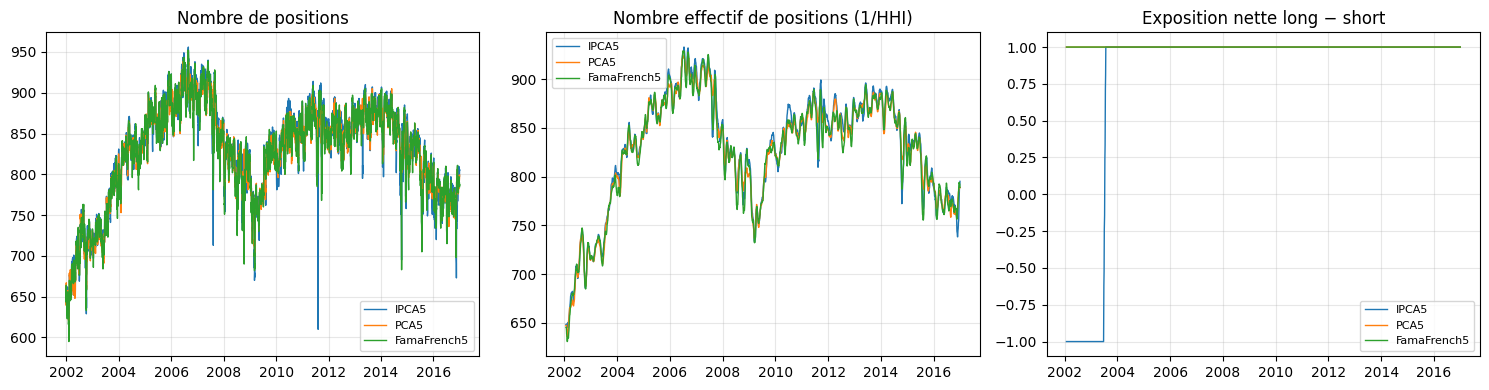

In [23]:
if weight_series:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for k, df in weight_series.items():
        axes[0].plot(df["positions"], label=k, lw=1)
        axes[1].plot(df["nb effectif (1/HHI)"].rolling(21).mean(), label=k, lw=1)
        axes[2].plot((df["long"] - df["short"]).rolling(21).mean(), label=k, lw=1)
    axes[0].set_title("Nombre de positions"); axes[1].set_title("Nombre effectif de positions (1/HHI)")
    axes[2].set_title("Exposition nette long − short")
    for a in axes: a.legend(fontsize=8)
    plt.tight_layout()

## 8. Sensibilité aux coûts de transaction

On recalcule le rendement net avec `r_net = r − c · turnover − h · part_short`, pour un coût c par unité de
turnover et un coût h de détention des positions courtes. C'est la même formule que `trans_cost` /
`hold_cost` dans le code, mais appliquée après coup : le modèle n'a pas été entraîné avec ces coûts.

coût (bp par unité de turnover),0,1,2,3,5,10
IPCA5,0.64,0.45,0.40,0.34,0.22,-0.07
PCA5,0.85,0.69,0.54,0.39,0.08,-0.68
FamaFrench5,0.19,0.16,0.12,0.09,0.02,-0.15


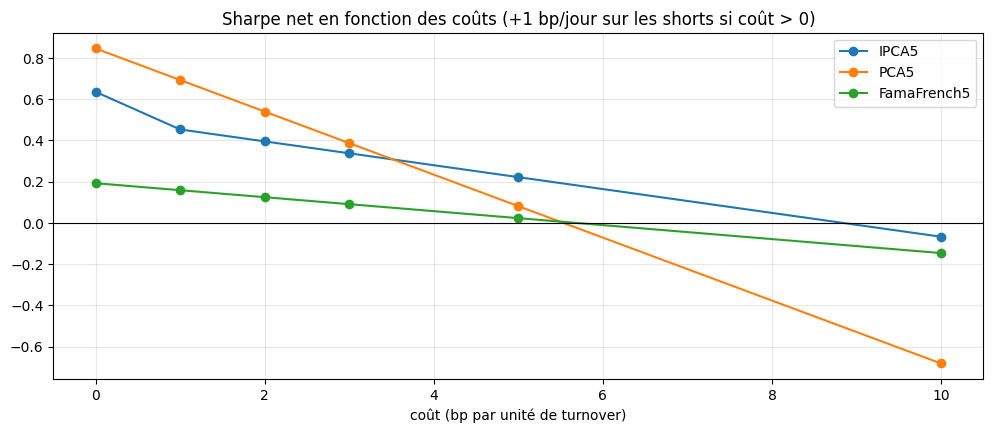

In [24]:
costs_bp = [0, 1, 2, 3, 5, 10]
sens = pd.DataFrame({k: [metrics(v["returns"] - c * 1e-4 * v["turnover"] - 1e-4 * v["short_proportion"] * (c > 0))["Sharpe"]
                         for c in costs_bp] for k, v in res.items()},
                    index=pd.Index(costs_bp, name="coût (bp par unité de turnover)"))
ax = sens.plot(marker="o", title="Sharpe net en fonction des coûts (+1 bp/jour sur les shorts si coût > 0)")
ax.axhline(0, color="k", lw=0.8)
sens.T.style.format("{:.2f}")

## 9. Comparaison avec des stratégies de référence

Ces stratégies sont calculées sur **les mêmes résidus et la même période de test**, avec les mêmes features OU
(`preprocess_ou`, fenêtre de 30 jours, aucune donnée future) :

| Stratégie | Règle |
|---|---|
| **OU seuil ±1,25** | Avellaneda-Lee simplifié : s = (x − μ)/σ ; long si s < −1,25, short si s > 1,25 |
| **OU linéaire** | w ∝ −s (borné à ±5) |
| **Reversal 30 j** | w ∝ −(résidu cumulé sur la fenêtre) |
| **Long 1/N** | poids égal sur tous les résidus sélectionnables |

Comme pour le modèle, les poids sont normalisés à Σ|w| = 1 chaque jour.

In [25]:
def baseline_strategies(R, lookback=LOOKBACK, start=LENGTH_TRAINING, s_open=1.25):
    R = R[:, np.count_nonzero(R, axis=0) >= lookback]
    windows, sel = preprocess_ou(R, lookback)
    sel = sel.numpy()
    x, mu, sigma = windows[..., 0], windows[..., 1], windows[..., 2]
    with np.errstate(divide="ignore", invalid="ignore"):
        s = np.nan_to_num(np.where(sel, (x - mu) / sigma, 0.0), nan=0.0, posinf=0.0, neginf=0.0)
    raw = {
        "OU seuil ±1,25": np.where(s > s_open, -1.0, np.where(s < -s_open, 1.0, 0.0)) * sel,
        "OU linéaire": -np.clip(s, -5, 5) * sel,
        "Reversal 30 j": -x * sel,
        "Long 1/N": sel.astype(np.float32),
    }
    k0 = start - lookback          # windows[k] utilise les jours k..k+lookback-1 et trade le jour k+lookback
    out = {}
    for name, w in raw.items():
        w = w[k0:].astype(np.float64)
        gross = np.abs(w).sum(1, keepdims=True)
        w = np.divide(w, gross, out=np.zeros_like(w), where=gross > 0)
        idx = dates[start:]
        out[name] = {"returns": pd.Series((w * R[start:]).sum(1), index=idx),
                     "turnover": pd.Series(np.r_[0, np.abs(np.diff(w, axis=0)).sum(1)], index=idx),
                     "short_proportion": pd.Series(np.abs(np.minimum(w, 0)).sum(1), index=idx)}
    return out

t0 = time.perf_counter()
baselines = {k: baseline_strategies(residuals[k]) for k in res if k in residuals}
print(f"Stratégies de référence calculées en {time.perf_counter() - t0:.0f} s")

Stratégies de référence calculées en 6 s


In [26]:
rows = []
for k in baselines:
    rows.append({"résidus": k, "stratégie": MODEL_NAME, **metrics(res[k]["returns"], res[k]["turnover"], res[k]["short_proportion"])})
    for b, v in baselines[k].items():
        r = v["returns"].loc[res[k]["returns"].index]
        rows.append({"résidus": k, "stratégie": b, **metrics(r, v["turnover"], v["short_proportion"])})
comparison = pd.DataFrame(rows).set_index(["résidus", "stratégie"])
comparison[["Sharpe", "Rendement ann. (%)", "Volatilité ann. (%)", "Max drawdown (%)", "Turnover moyen", "Part short moyenne"]] \
    .style.format("{:.2f}").background_gradient(subset=["Sharpe"], cmap="Greens")

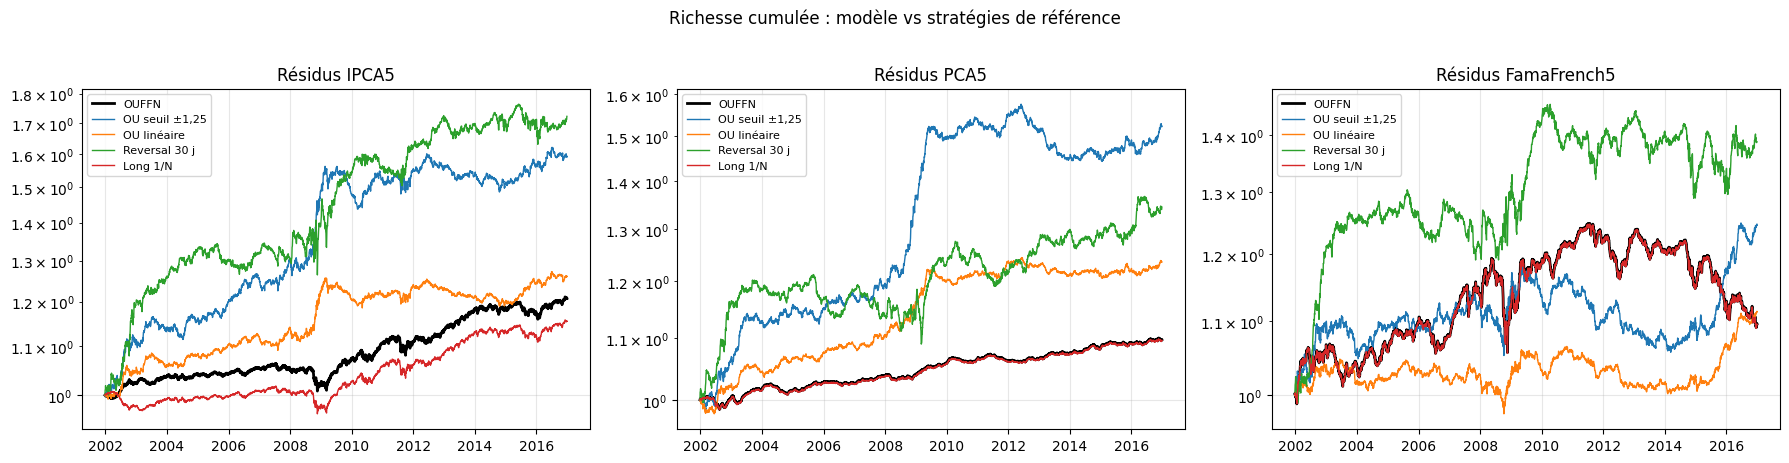

In [27]:
fig, axes = plt.subplots(1, len(baselines), figsize=(6 * len(baselines), 4.5), squeeze=False)
for ax, k in zip(axes[0], baselines):
    r = res[k]["returns"]
    ax.plot((1 + r).cumprod(), lw=2, color="k", label=MODEL_NAME)
    for b, v in baselines[k].items():
        ax.plot((1 + v["returns"].loc[r.index]).cumprod(), lw=1, label=b)
    ax.set_yscale("log"); ax.set_title(f"Résidus {k}"); ax.legend(fontsize=8)
plt.suptitle("Richesse cumulée : modèle vs stratégies de référence", y=1.02)
plt.tight_layout()

In [28]:
# Corrélation entre le modèle et les stratégies de référence
for k in baselines:
    df = pd.DataFrame({MODEL_NAME: res[k]["returns"], **{b: v["returns"] for b, v in baselines[k].items()}}).dropna()
    print(f"Résidus {k} — corrélation des rendements quotidiens avec {MODEL_NAME} :")
    print(df.corr()[MODEL_NAME].drop(MODEL_NAME).round(2).to_string(), "\n")

Résidus IPCA5 — corrélation des rendements quotidiens avec OUFFN :
OU seuil ±1,25   0.0500
OU linéaire      0.0300
Reversal 30 j    0.1900
Long 1/N         0.9200 

Résidus PCA5 — corrélation des rendements quotidiens avec OUFFN :
OU seuil ±1,25   -0.0000
OU linéaire      -0.0100
Reversal 30 j     0.0300
Long 1/N          1.0000 

Résidus FamaFrench5 — corrélation des rendements quotidiens avec OUFFN :
OU seuil ±1,25   -0.0200
OU linéaire      -0.0400
Reversal 30 j     0.2200
Long 1/N          1.0000 



## 10. Synthèse

In [29]:
best = summary["Sharpe"].idxmax()
print(f"Modèle : {MODEL_NAME} — {cfg_run['num_epochs']} époques, objectif '{cfg_run['objective']}', "
      f"fenêtre d'entraînement {cfg_run['length_training']} j, réentraînement tous les {cfg_run['retrain_freq']} j")
print(f"Période de test : {dates[-len(next(iter(res.values()))['returns'])]:%Y-%m-%d} → {dates[-1]:%Y-%m-%d}\n")
for k in summary.index:
    s = summary.loc[k]
    line = (f"  {k:<12} Sharpe {s['Sharpe']:5.2f} | rendement {s['Rendement ann. (%)']:5.2f} % | "
            f"vol {s['Volatilité ann. (%)']:5.2f} % | max DD {s['Max drawdown (%)']:6.2f} %")
    if k in baselines:
        b_sh = comparison.loc[k]["Sharpe"].drop(MODEL_NAME)
        line += f" | meilleure référence : {b_sh.idxmax()} ({b_sh.max():.2f})"
    print(line)
print(f"\nMeilleur jeu de résidus pour {MODEL_NAME} : {best}")
for k in baselines:
    c = res[k]["returns"].corr(baselines[k]["Long 1/N"]["returns"])
    if c > 0.9:
        print(f"⚠ {k} : corrélation {c:.2f} avec 'Long 1/N' et part short {summary.loc[k, 'Part short moyenne']:.2f} — "
              "le modèle a convergé vers une allocation quasi uniforme (solution dégénérée), pas vers un signal d'arbitrage.")

Modèle : OUFFN — 100 époques, objectif 'sharpe', fenêtre d'entraînement 1000 j, réentraînement tous les 125 j
Période de test : 2001-12-26 → 2016-12-30

  IPCA5        Sharpe  0.64 | rendement  1.28 % | vol  2.01 % | max DD  -5.23 % | meilleure référence : OU seuil ±1,25 (0.80)
  PCA5         Sharpe  0.85 | rendement  0.62 % | vol  0.73 % | max DD  -1.97 % | meilleure référence : OU seuil ±1,25 (1.10)
  FamaFrench5  Sharpe  0.19 | rendement  0.67 % | vol  3.51 % | max DD -12.65 % | meilleure référence : Reversal 30 j (0.49)

Meilleur jeu de résidus pour OUFFN : PCA5
⚠ IPCA5 : corrélation 0.92 avec 'Long 1/N' et part short 0.10 — le modèle a convergé vers une allocation quasi uniforme (solution dégénérée), pas vers un signal d'arbitrage.
⚠ PCA5 : corrélation 1.00 avec 'Long 1/N' et part short 0.00 — le modèle a convergé vers une allocation quasi uniforme (solution dégénérée), pas vers un signal d'arbitrage.
⚠ FamaFrench5 : corrélation 1.00 avec 'Long 1/N' et part short 0.00 — le modèle 

**À garder en tête pour interpréter ces chiffres**

- Les résultats du papier sont obtenus avec `use_residual_weights: True`, ce qui suppose les matrices de
  composition, non publiées. Turnover et part courte ne sont donc **pas comparables** à ceux du papier.
- **Solution dégénérée** : si le modèle est presque parfaitement corrélé à « Long 1/N » (voir ci-dessus),
  le réseau donne à peu près le même poids positif à tous les actifs, au lieu d'exploiter le signal OU.
  Avec OUFFN (65 paramètres, sigmoïdes, dropout 0,25) et une seule graine, c'est ce qui se produit ici
  sur PCA 5 et Fama-French 5.
- Une seule graine aléatoire (`random_seed = 0`) est utilisée : avec un petit réseau comme OUFFN, la variance
  d'un entraînement à l'autre peut être importante.
- Pour comparer les modèles, relancez la section 5 avec une autre `CONFIG` (`fourierffn-full.yaml`,
  `rawffn-full.yaml`, `cnntransformer-full.yaml`) et `RUN_BACKTEST = True`. Le CNN+Transformer, modèle
  principal du papier, est nettement plus long à entraîner ; `DEVICE = "mps"` peut aider.